# 2.10. Оценщики на основе ML-моделей

**План занятия**

1. Двойная робастная оценка: как объединить модель исхода и propensity score.
2. Кросс-фиттинг и ML в двойной робастной оценке.
3. Трансформация цели: plug-and-play оценка CATE.
4. Непрерывное воздействие и нелинейные эффекты.
5. Causal Impact: байесовские структурные временные ряды.
6. Как проверять Causal Impact плацебо-датами.

### Библиотеки

Кроме стандартного набора нужны `lightgbm`, `pycausalimpact` и `openpyxl`. В Colab их можно поставить командой `!pip install -q lightgbm pycausalimpact openpyxl`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from causalimpact import CausalImpact
from ipywidgets import FloatSlider, interact
from lightgbm import LGBMClassifier, LGBMRegressor
from scipy.special import expit
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict, train_test_split

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
DATA = 'data/'
rng = np.random.default_rng(42)

## Двойная робастная оценка

**Doubly Robust Estimation** объединяет модель исхода и propensity score так, что для состоятельности достаточно, чтобы верна была **хотя бы одна из двух моделей**.

Вернёмся к эксперименту с мышлением роста из лекции 2.09. Напомним: возможность посетить семинар случайна, а само посещение нет, поэтому посетившие и не посетившие различаются. Сравним подходы на этих данных. Данные смоделированы Эйти и Вейджером, реальные закрыты.

In [2]:
data = pd.read_csv(DATA + 'learning_mindset.csv')
categ = ['ethnicity', 'gender', 'school_urbanicity']
features = pd.get_dummies(data.drop(columns=['schoolid', 'intervention', 'achievement_score']), columns=categ).astype(float)

T = data['intervention'].to_numpy()
Y = data['achievement_score'].to_numpy()
schools = data['schoolid'].to_numpy()
X = features.to_numpy()
print(data.shape, 'школ:', data['schoolid'].nunique())

(10391, 13) школ: 76


### Формула

Двойная робастная оценка выглядит так:

$$
\hat{ATE} = \frac{1}{N}\sum \bigg( \dfrac{T_i(Y_i - \hat{\mu_1}(X_i))}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg) - \frac{1}{N}\sum \bigg( \dfrac{(1-T_i)(Y_i - \hat{\mu_0}(X_i))}{1-\hat{P}(X_i)} + \hat{\mu_0}(X_i) \bigg)
$$

где $\hat{P}(x)$ — оценка propensity score, а $\hat{\mu_1}(x)$ и $\hat{\mu_0}(x)$ — оценки $E[Y|X, T=1]$ и $E[Y|X, T=0]$. Первая часть оценивает $E[Y_1]$, вторая $E[Y_0]$. Рассмотрим первую, вторая устроена так же:

$$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_i(Y_i - \hat{\mu_1}(X_i))}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg)
$$

**Пусть верна модель исхода $\hat{\mu_1}$, а $\hat{P}$ неверна.** Среди получивших воздействие остаток $Y_i - \hat{\mu_1}(X_i)$ при каждом $X$ имеет нулевое среднее, поэтому первое слагаемое в среднем равно нулю при любых весах. Остаётся $\hat{\mu_1}(X_i)$, которая и оценивает $E[Y_1]$.

**Пусть верен propensity score, а $\hat{\mu_1}$ неверна.** Переставим члены:

$$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_iY_i}{\hat{P}(X_i)} - \bigg(\dfrac{T_i}{\hat{P}(X_i)} - 1\bigg) \hat{\mu_1}(X_i) \bigg)
= \frac{1}{N}\sum \bigg( \dfrac{T_iY_i}{\hat{P}(X_i)} - \bigg(\dfrac{T_i - \hat{P}(X_i)}{\hat{P}(X_i)}\bigg) \hat{\mu_1}(X_i) \bigg)
$$

Если скор верен, то $E[T_i - \hat{P}(X_i) | X_i]=0$, и слагаемое с $\hat{\mu_1}$ в среднем исчезает при любой функции от $X$. Остаётся оценка IPTW $\frac{T_iY_i}{\hat{P}(X_i)}$, а она верна по предположению.

Если неверны **обе** модели, никаких гарантий нет. И в обоих случаях нужно, чтобы все конфаундеры были измерены: двойная робастность защищает от ошибки формы модели, а не от пропущенной переменной.

In [3]:
def doubly_robust(t, y, ps, mu0, mu1):
    return np.mean(t * (y - mu1) / ps + mu1) - np.mean((1 - t) * (y - mu0) / (1 - ps) + mu0)


def fit_nuisances(t, y, x):
    """Оценивает propensity score и модели исхода на тех же данных."""
    ps = LogisticRegression(C=1e6, max_iter=2000).fit(x, t).predict_proba(x)[:, 1]
    mu0 = LinearRegression().fit(x[t == 0], y[t == 0]).predict(x)
    mu1 = LinearRegression().fit(x[t == 1], y[t == 1]).predict(x)
    return ps, mu0, mu1

In [4]:
def three_estimates(t, y, x, local_rng):
    """Считает оценку с верными моделями, со случайным скором и со случайной моделью исхода."""
    ps, mu0, mu1 = fit_nuisances(t, y, x)
    random_ps = local_rng.uniform(0.1, 0.9, len(t))
    random_mu0, random_mu1 = local_rng.normal(0, 1, len(t)), local_rng.normal(0, 1, len(t))
    return (doubly_robust(t, y, ps, mu0, mu1),
            doubly_robust(t, y, random_ps, mu0, mu1),
            doubly_robust(t, y, ps, random_mu0, random_mu1))


school_rows = [np.flatnonzero(schools == school) for school in np.unique(schools)]
boot_rng = np.random.default_rng(88)

point = three_estimates(T, Y, X, boot_rng)
boot = []
for _ in range(200):
    rows = np.concatenate([school_rows[i] for i in boot_rng.integers(0, len(school_rows), len(school_rows))])
    boot.append(three_estimates(T[rows], Y[rows], X[rows], boot_rng))
boot = np.array(boot)

pd.DataFrame({'Вариант': ['Обе модели оценены', 'Случайный скор из U(0.1, 0.9)', 'Случайная модель исхода из N(0, 1)'],
              'Оценка': point, 'SE': boot.std(axis=0),
              'ДИ 2.5%': np.percentile(boot, 2.5, axis=0), 'ДИ 97.5%': np.percentile(boot, 97.5, axis=0)}).round(3)

,Вариант,Оценка,SE,ДИ 2.5%,ДИ 97.5%
0,Обе модели оценены,0.388,0.028,0.337,0.443
1,"Случайный скор из U(0.1, 0.9)",0.415,0.030,0.321,0.436
2,"Случайная модель исхода из N(0, 1)",0.354,0.032,0.331,0.451


Здесь два намеренно сломанных варианта. В одном вместо propensity score стоит случайное число от 0.1 до 0.9, в другом вместо моделей исхода — случайный шум. Бутстреп здесь выбирает школы целиком.

Две сломанные версии дали 0.415 и 0.354 при обычной оценке 0.388, а бутстреп-интервалы почти совпали: около [0.33, 0.44]. Здесь спасает то, что вторая модель в каждом случае верна.

Но это только наблюдение на одном наборе данных, где мы не знаем истину и где смещение невелико. Проверим двойную робастность на симуляции с известным эффектом 1. Здесь и отбор, и исход зависят от $x^2$. «Верная» модель содержит $x^2$, а «неверная» только $x$. Подвигайте силу нелинейности.

In [5]:
def simulate_dr(strength, n=2000, reps=150, seed=5):
    """Сравнивает оценки при верных и неверных моделях при известном эффекте 1."""
    local = np.random.default_rng(seed)
    results = {name: [] for name in ['Наивно', 'Обе верны', 'Верен только скор', 'Верен только исход', 'Обе неверны']}
    for _ in range(reps):
        x = local.normal(0, 1, n)
        t = (local.random(n) < expit(strength * (x ** 2 - 1))).astype(int)
        y = 1 + t + strength * x ** 2 + local.normal(0, 1, n)

        right, wrong = np.column_stack([x, x ** 2]), x.reshape(-1, 1)
        ps_right = LogisticRegression(C=1e6).fit(right, t).predict_proba(right)[:, 1]
        ps_wrong = LogisticRegression(C=1e6).fit(wrong, t).predict_proba(wrong)[:, 1]
        mu_right = [LinearRegression().fit(right[t == v], y[t == v]).predict(right) for v in (0, 1)]
        mu_wrong = [LinearRegression().fit(wrong[t == v], y[t == v]).predict(wrong) for v in (0, 1)]

        results['Наивно'].append(y[t == 1].mean() - y[t == 0].mean())
        results['Обе верны'].append(doubly_robust(t, y, ps_right, *mu_right))
        results['Верен только скор'].append(doubly_robust(t, y, ps_right, *mu_wrong))
        results['Верен только исход'].append(doubly_robust(t, y, ps_wrong, *mu_right))
        results['Обе неверны'].append(doubly_robust(t, y, ps_wrong, *mu_wrong))
    return pd.DataFrame(results)


def plot_dr(ax, strength):
    results = simulate_dr(strength)
    ax.boxplot(results.to_numpy(), vert=False, tick_labels=results.columns, showfliers=False,
               medianprops=dict(color='black'), boxprops=dict(color=BLUE), whiskerprops=dict(color=BLUE))
    ax.axvline(1, color=GREEN, ls='--', lw=2, label='Истинный эффект')
    ax.invert_yaxis()
    ax.set_xlabel('Оценка эффекта')
    ax.set_title(f'Сила нелинейности {strength}', fontsize=12)
    return results


def dr_demo(strength=1.0):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    plot_dr(ax, strength)
    ax.legend()
    plt.show()


interact(dr_demo, strength=FloatSlider(value=1, min=0, max=2, step=0.25, description='Сила'));

Статичная версия при силе 1 и средние значения оценок.

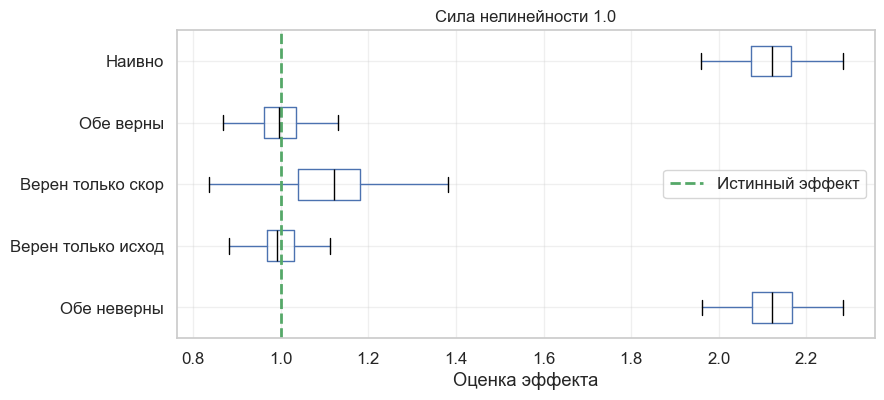

,Наивно,Обе верны,Верен только скор,Верен только исход,Обе неверны
mean,2.122,1.002,1.034,0.997,2.123
std,0.071,0.072,0.548,0.051,0.070


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
dr_results = plot_dr(ax, 1.0)
ax.legend()
plt.show()
dr_results.agg(['mean', 'std']).round(3)

Наивная оценка равна 2.1 при настоящем эффекте 1. Если верна хотя бы одна модель, оценка возвращается к 1: 1.03 и 1.00. Если неверны обе, получаем те же 2.1, что и наивно. Заметьте цену: если верен только скор, разброс оценки в 8 раз больше, чем при верной модели исхода: SD 0.55 против 0.05.

### Кросс-фиттинг

Пока мы использовали линейные модели. Формула двойной робастности позволяет брать гибкие ML-модели, и в этом главная практическая ценность. Но есть ловушка: модель учится и предсказывает на одних и тех же данных. Переобученный бустинг запомнит исход и воздействие, и остаток $Y_i - \hat{\mu}(X_i)$ станет искусственно мал.

Решение — **кросс-фиттинг (cross-fitting)** из Double ML: делим данные на фолды, а прогноз для объекта делаем моделью, обученной на других фолдах. Деление проводим по школам, чтобы ученики одной школы не попадали и в обучение, и в проверку.

In [7]:
def cross_fit(t, y, x, groups, n_splits=5):
    """Получает прогнозы скора и исхода моделями, не видевшими объект."""
    folds = list(GroupKFold(n_splits=n_splits).split(x, t, groups))
    params = dict(n_estimators=100, max_depth=3, learning_rate=0.05, verbose=-1, random_state=0)
    ps = cross_val_predict(LGBMClassifier(**params), x, t, cv=folds, method='predict_proba')[:, 1]
    mu0, mu1 = np.zeros(len(t)), np.zeros(len(t))
    for train_idx, test_idx in folds:
        for value, target in [(0, mu0), (1, mu1)]:
            part = train_idx[t[train_idx] == value]
            target[test_idx] = LGBMRegressor(**params).fit(x[part], y[part]).predict(x[test_idx])
    return np.clip(ps, 0.01, 0.99), mu0, mu1


linear_nuisances = fit_nuisances(T, Y, X)
booster_nuisances = cross_fit(T, Y, X, schools)
print('Линейные модели:          ', round(doubly_robust(T, Y, *linear_nuisances), 4))
print('Бустинг с кросс-фиттингом:', round(doubly_robust(T, Y, *booster_nuisances), 4))

Линейные модели:           0.3882
Бустинг с кросс-фиттингом: 0.3827


## Plug-and-Play оценка CATE

До сих пор мы устраняли смещение, чтобы найти средний эффект. Для этого единицы должны быть взаимозаменяемы при данных признаках: $Y(0), Y(1) \perp T | X$. Средний эффект полезен, чтобы решить, запускать ли нововведение. Но часто нужно больше: понять, кто реагирует лучше, а кто хуже, и воздействовать только на них.

Поэтому от ATE переходим к CATE. Если воздействие — препарат, нужно знать, какие пациенты чувствительнее и есть ли те, кому он вредит.

CATE можно получить из линейной регрессии со взаимодействием:

$$y_i = \beta_0 + \beta_1 t_i + \beta_2 X_i + \beta_3 t_i X_i + e_i, \qquad \hat{\tau}(x) = \hat{\beta}_1 + \hat{\beta}_3 X_i$$

Главный недостаток в предположении о линейности. Было бы здорово взять бустинг или нейросеть: $y_i = M(X_i, T_i) + e_i$. Но такая модель предсказывает $\hat{y}$, а не $\hat{\tau}(x)$. В идеале мы бы минимизировали $E[(\tau(x)_i - \hat{\tau}(x)_i)^2]$, но $\tau_i$ ненаблюдаем. Попробуем что-нибудь придумать.

### Трансформация цели

Пусть воздействие бинарно. Инвестиционная компания рассылает письма с финансовым образованием и надеется, что клиенты начнут инвестировать. Эксперимент рандомизирован, 50% клиентов получили письмо.

Преобразуем исход:

$$Y^*_i = 2 Y_i T_i - 2 Y_i (1-T_i)$$

Посмотрим, что это даёт. Благодаря случайному назначению $T \perp Y(0), Y(1)$, а значит $E[T \cdot Y(t)]=E[T]E[Y(t)]$. Кроме того, $Y_i T_i = Y(1)_i T_i$ и $Y_i(1-T_i) = Y(0)_i(1-T_i)$: воздействие материализует один из исходов. Возьмём условное среднее:

$$
\begin{align}
E[Y^*_i|X_i=x] &= E[2 Y(1)_i T_i - 2 Y(0)_i(1-T_i)|X_i=x] \\
&= 2E[Y(1)_i T_i | X_i=x] - 2E[Y(0)_i(1-T_i)|X_i=x]\\
&= 2E[Y(1)_i| X_i=x] E[ T_i | X_i=x] - 2E[Y(0)_i| X_i=x]E[(1-T_i)|X_i=x] \\
&= 2E[Y(1)_i| X_i=x] \cdot 0.5 - 2E[Y(0)_i| X_i=x] \cdot 0.5 \\
&= E[Y(1)_i| X_i=x] - E[Y(0)_i| X_i=x] \\
&= \tau(x)
\end{align}
$$

Итак, среднее $Y^*$ при данном $X$ равно CATE. Сам $Y^*_i$ не равен индивидуальному эффекту, это его очень шумная несмещённая оценка. Теперь можно минимизировать $E[(Y^*_i - \hat{\tau}(x)_i)^2]$: берём любую ML-регрессию, предсказываем $Y^*$, и её прогноз будет оценкой CATE.

Если воздействие не 50 на 50 или назначается неслучайно, но выполнена условная независимость $T \perp Y(1), Y(0) | X$, преобразование обобщается:

$$
Y^*_i = Y_i \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}
$$

где $e(X_i)$ — propensity score. Если рандомизация с вероятностью $p$, просто подставляем $p$. Проверим:

$$
\begin{align}
E[Y^*_i|X_i=x] &= E\big[Y_i \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big] \\
&= E\big[Y_i T_i \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))} + Y_i (1-T_i) \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big]\\
&= E\big[Y(1)_i \dfrac{T_i(1 - e(X_i))}{e(X_i)(1-e(X_i))} | X_i=x\big] - E\big[Y(0)_i \dfrac{(1-T_i)e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big]\\
&= \dfrac{1}{e(X_i)} E[Y(1)_i T_i|X_i=x] - \dfrac{1}{1-e(X_i)} E[Y(0)_i (1-T_i)|X_i=x]\\
&= \dfrac{1}{e(X_i)} E[Y(1)_i|X_i=x] E[T_i|X_i=x] - \dfrac{1}{1-e(X_i)} E[Y(0)_i|X_i=x] E[(1-T_i)| X_i=x]\\
&= E[Y(1)_i|X_i=x] - E[Y(0)_i|X_i=x]\\
&= \tau(x)
\end{align}
$$

Рассмотрим пример. Исход бинарный: `converted` показывает, инвестировал ли клиент. Наша цель — персонализация: отправлять письмо `em1` только тем, кто лучше на него реагирует. Поэтому оцениваем $\tau(x) = E[Conv(1)_i - Conv(0)_i|X_i=x]$. Делим данные на обучение и проверку.

In [8]:
def effect_slope(df, y, t):
    """Считает наклон регрессии y на t: оценку эффекта внутри группы."""
    return (np.sum((df[t] - df[t].mean()) * (df[y] - df[y].mean())) /
            np.sum((df[t] - df[t].mean()) ** 2))


def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    """Строит кривую кумулятивного прироста при сортировке по оценке CATE."""
    size = dataset.shape[0]
    ordered = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    return np.array(n_rows) / size * 100, np.array([effect_slope(ordered.head(rows), y, t) * (rows / size) for rows in n_rows])


def plot_gain(ax, curves, baseline, title):
    for (share, gain), color, label in curves:
        ax.plot(share, gain, color=color, lw=2.5, label=label)
    ax.plot([0, 100], [0, baseline], ls='--', color='black', label='Случайный порядок')
    ax.set_xlabel('Доля выборки, %')
    ax.set_ylabel('Кумулятивный прирост')
    ax.set_title(title, fontsize=12)
    ax.legend()


email = pd.read_csv(DATA + 'invest_email_rnd.csv')
train, test = train_test_split(email, test_size=0.4, random_state=123)
print(train.shape, test.shape)
email.head()

(9000, 8) (6000, 8)


,age,income,insurance,invested,em1,em2,em3,converted
0,44.1,5483.80,6155.29,14294.81,0,1,1,0
1,39.8,2737.92,50069.40,7468.15,1,0,0,0
2,49.0,2712.51,5707.08,5095.65,1,0,1,1
3,39.7,2326.37,15657.97,6345.20,1,1,1,0
4,35.3,2787.26,27074.44,14114.86,1,1,1,0


Письма распределялись случайно, хотя и не точно поровну, поэтому propensity score постоянен и равен доле получивших письмо. Применяем преобразование и учим бустинг.

In [9]:
outcome = 'converted'
treatment = 'em1'
email_features = ['age', 'income', 'insurance', 'invested']
params = dict(max_depth=3, min_child_samples=300, num_leaves=5, verbose=-1, random_state=123)

p = train[treatment].mean()
y_star_train = train[outcome] * (train[treatment] - p) / (p * (1 - p))
cate_learner = LGBMRegressor(**params).fit(train[email_features], y_star_train)

test_pred = test.assign(cate=cate_learner.predict(test[email_features]))
train_pred = train.assign(cate=cate_learner.predict(train[email_features]))
print('Среднее Y* на обучении:', round(y_star_train.mean(), 4), ' ATE на обучении:', round(effect_slope(train, outcome, treatment), 4))
test_pred[email_features + ['cate']].head()

Среднее Y* на обучении: 0.071  ATE на обучении: 0.071


,age,income,insurance,invested,cate
6958,40.9,4486.14,37320.33,12559.25,0.105665
7534,42.6,6386.19,13270.47,29114.42,0.121922
2975,47.6,1900.26,25588.72,2420.39,0.034161
3903,41.0,5802.19,57087.37,20182.20,0.046805
8437,49.1,2202.96,5050.81,9245.88,-0.009099


У разных клиентов оценка CATE отличается. Она показывает, на сколько вырастет вероятность инвестиции, если отправить письмо.

Качество CATE нельзя проверить напрямую: истинный эффект никто не видел. Поэтому используют **кривую кумулятивного прироста**: сортируем клиентов по оценке CATE и смотрим, насколько эффект в верхней группе выше среднего. Чем дальше кривая над пунктиром, тем лучше модель упорядочивает клиентов. Пунктир соответствует случайному порядку.

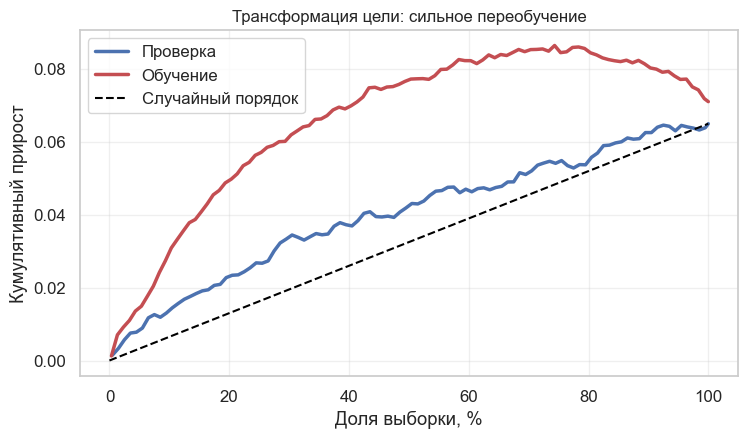

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(cumulative_gain(test_pred, 'cate', outcome, treatment), BLUE, 'Проверка'),
               (cumulative_gain(train_pred, 'cate', outcome, treatment), RED, 'Обучение')],
          effect_slope(test, outcome, treatment), 'Трансформация цели: сильное переобучение');

На проверке модель лучше случайного порядка, но ненамного. На обучении кривая гораздо выше: модель сильно переобучается.

Причина в цене метода: $Y^*$ — очень шумная оценка индивидуального эффекта. Дисперсию можно снизить, если вычесть из исхода его прогноз. Преобразованная цель при этом остаётся несмещённой, потому что при случайном $T$ прогноз $\hat{m}(X)$ не меняет среднего:

$$
Y^*_i = (Y_i - \hat{m}(X_i)) \dfrac{T_i - p}{p(1-p)}
$$

Это упрощённый вариант R-learner и DR-learner, которые мы обсудим в следующей лекции. Прогноз получаем кросс-фиттингом.

Дисперсия Y*:               0.564
Дисперсия Y* после вычитания: 0.478


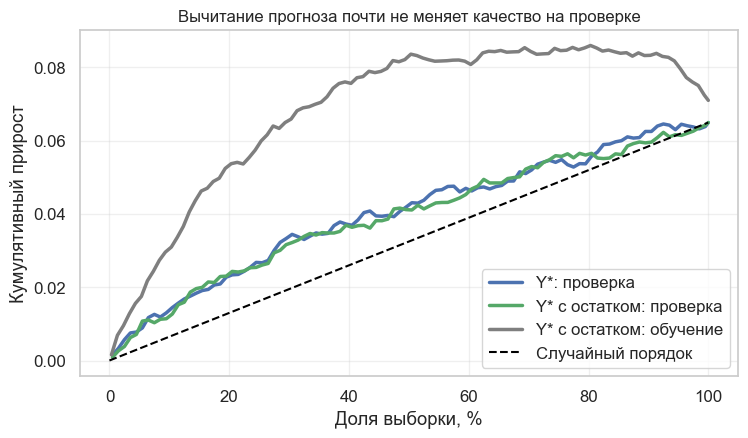

In [11]:
baseline = cross_val_predict(LGBMRegressor(**params), train[email_features], train[outcome], cv=5)
y_star_residual = (train[outcome] - baseline) * (train[treatment] - p) / (p * (1 - p))
residual_learner = LGBMRegressor(**params).fit(train[email_features], y_star_residual)

print('Дисперсия Y*:              ', round(y_star_train.var(), 3))
print('Дисперсия Y* после вычитания:', round(y_star_residual.var(), 3))

test_residual = test.assign(cate=residual_learner.predict(test[email_features]))
train_residual = train.assign(cate=residual_learner.predict(train[email_features]))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(cumulative_gain(test_pred, 'cate', outcome, treatment), BLUE, 'Y*: проверка'),
               (cumulative_gain(test_residual, 'cate', outcome, treatment), GREEN, 'Y* с остатком: проверка'),
               (cumulative_gain(train_residual, 'cate', outcome, treatment), GRAY, 'Y* с остатком: обучение')],
          effect_slope(test, outcome, treatment), 'Вычитание прогноза почти не меняет качество на проверке');

Дисперсия упала только с 0.56 до 0.48, потому что признаки слабо предсказывают `converted`, и на проверке кривые почти совпали. Эта поправка помогает тогда, когда исход хорошо предсказуем. Здесь проблема глубже: при 9000 объектах и слабой неоднородности данных для точной оценки CATE просто мало.

### Непрерывное воздействие

Трансформация цели выше работает только для бинарного воздействия. Материалов о непрерывном случае меньше. Matheus Facure предлагает практический приём, подчёркивая, что серьёзного эконометрического обоснования у него нет.

Рассмотрим продажи мороженого. Цена назначалась случайно, строка данных — это день, и мы хотим знать, в какие дни покупатели менее чувствительны к цене.

In [12]:
prices_rnd = pd.read_csv(DATA + 'ice_cream_sales_rnd.csv')
train, test = train_test_split(prices_rnd, test_size=0.3, random_state=123)
print(train.shape, test.shape)
prices_rnd.head()

(3500, 5) (1500, 5)


,temp,weekday,cost,price,sales
0,25.8,1,0.3,7,230
1,22.7,3,0.5,4,190
2,33.7,7,1.0,5,237
3,23.0,4,0.5,5,193
4,24.4,1,1.0,3,252


Сначала пусть исход зависит от воздействия линейно. Есть два типа дней: жаркие (жёлтые) и холодные (синие). В холодные дни люди чувствительнее к росту цен, а спрос падает с ценой линейно.

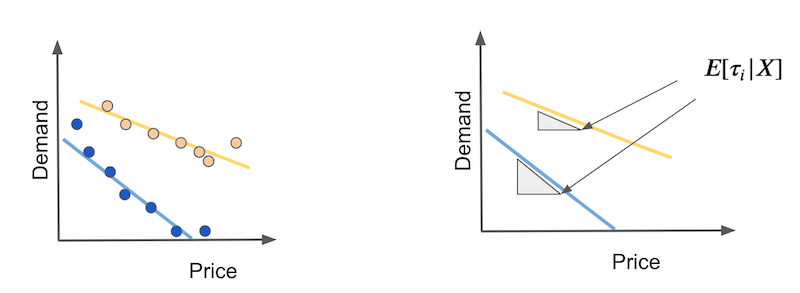

Тогда CATE — это наклон линии спроса, его можно оценить простой регрессией отдельно для жарких и холодных дней.

$$
\hat{\tau(x)} = Cov(Y_i, T_i)/Var(T_i) = \dfrac{\sum(Y_i- \bar{Y})(T_i - \bar{T})}{\sum (T_i - \bar{T})^2}
$$


Запишем похожую величину для отдельного объекта:

$$
Y^*_i = (Y_i- \bar{Y})\dfrac{(T_i - \bar{T})}{\sigma^2_T}
$$

Вычитаем из исхода среднее, умножаем на центрированное воздействие и делим на дисперсию воздействия.

Обозначим $V_i = (T_i - \bar{T})/\sigma^2_T$. При случайном назначении $E[V_i|X_i=x]=0$. Кроме того, $E[T_i V_i | X_i=x]=1$, потому что $E[T_i(T_i - \bar{T})|X_i=x] = E[(T_i - \bar{T})^2|X_i=x]$. Также $E[e_i V_i | X_i=x]=0$ из-за независимости ошибки и воздействия.

Пусть для локальной линейной модели $Y_i = \alpha + \beta T_i + e_i | X_i=x$ нас интересует наклон $\beta$. Тогда

$$
\begin{align}
E[Y^*_i|X_i=x] &= E[(Y_i-\bar{Y})V_i | X_i=x] \\
&= E[(\alpha + \beta T_i + e_i - \bar{Y})V_i | X_i=x] \\
&= (\alpha - \bar{Y}) E[V_i | X_i=x] + \beta E[T_i V_i | X_i=x] + E[e_i V_i | X_i=x] \\
&= \beta = \tau(x)
\end{align}
$$

Без рандомизации $\bar{T}$ заменяют моделью $M(X_i)$, оценивающей $E[T_i|X_i=x]$, а знаменатель — условной дисперсией воздействия:

$$
Y^*_i = (Y_i- \hat{m}(X_i))\dfrac{T_i - M(X_i)}{\widehat{Var}(T_i | X_i)}
$$

Здесь нельзя делить на $(T_i - M(X_i))^2$ для каждого объекта: нужно среднее значение этой величины, то есть условная дисперсия. Иначе дробь превратится в $1/(T_i - M(X_i))$, а при значениях около нуля такая величина уходит в бесконечность. Проверим это на простой симуляции, где эффект равен -1 и -3.

In [13]:
n = 100_000
x = rng.integers(0, 2, n)
t = 2 + x + rng.normal(0, 1, n)
tau = -1 - 2 * x
y = 10 + 3 * x + tau * t + rng.normal(0, 1, n)

m = 10 + 3 * x + tau * (2 + x)  # настоящее E[Y|X]
residual_t = t - (2 + x)
correct = (y - m) * residual_t / 1
pointwise = (y - m) * residual_t / residual_t ** 2

pd.DataFrame({'Настоящий CATE': pd.Series(tau).groupby(x).mean(),
              'С условной дисперсией': pd.Series(correct).groupby(x).mean(),
              'С делением на квадрат остатка': pd.Series(pointwise).groupby(x).mean()}).round(3)

,Настоящий CATE,С условной дисперсией,С делением на квадрат остатка
0,-1.0,-1.013,-0.873
1,-3.0,-3.021,-2.512


С условной дисперсией оценка равна -1.01 и -3.02. С делением на квадрат остатка получаем -0.87 и -2.51, причём этот результат нестабилен: у отношения нормальных величин нет конечного среднего, поэтому цифра зависит от выборки.

Если нужно только упорядочить дни, а не узнать величину эффекта, знаменатель можно опустить: $Y^*_i = (Y_i- \bar{Y})(T_i - \bar{T})$. Цены здесь случайны, поэтому модель для них не нужна. Прогноз окажется масштабирован на $Var(T)$ и потеряет единицы измерения, но порядок дней это не меняет.

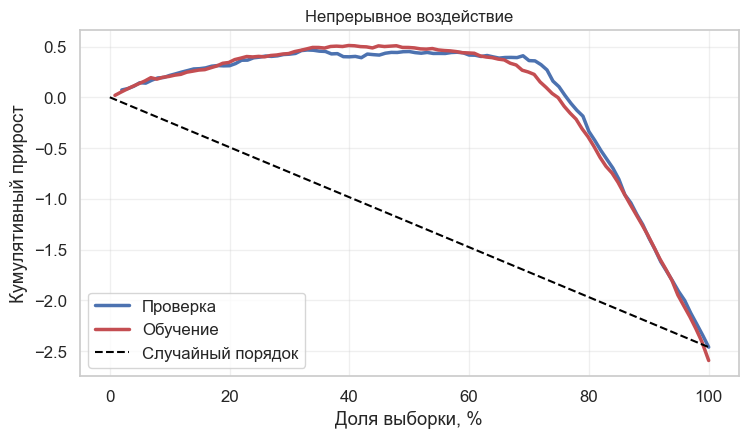

In [14]:
price_features = ['temp', 'weekday', 'cost']


def price_gain(data_train, data_test, target_train, y, t):
    """Учит модель на преобразованной цели и возвращает кривые для обеих частей."""
    learner = LGBMRegressor(**params).fit(data_train[price_features], target_train)
    return (cumulative_gain(data_test.assign(cate=learner.predict(data_test[price_features])), 'cate', y, t),
            cumulative_gain(data_train.assign(cate=learner.predict(data_train[price_features])), 'cate', y, t))


y_star_cont = (train['price'] - train['price'].mean()) * (train['sales'] - train['sales'].mean())
gain_test, gain_train = price_gain(train, test, y_star_cont, 'sales', 'price')

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_gain(ax, [(gain_test, BLUE, 'Проверка'), (gain_train, RED, 'Обучение')],
          effect_slope(test, 'sales', 'price'), 'Непрерывное воздействие');

Здесь модель намного лучше случайного порядка, а кривые обучения и проверки почти совпадают. Эффект цены отрицателен, поэтому кривая идёт вверх на первых группах и падает на последних: модель сверху ставит дни, в которые цена почти не важна. В отличие от случая с письмами, здесь дисперсия не мешает, но это особенность этих данных.

### Нелинейные эффекты воздействия

Мы предположили линейность эффекта, но это редко обосновано. Обычно эффект выходит на насыщение. Здесь разумно думать, что спрос падает быстрее при первых повышениях цены и медленнее потом. В данных это видно: от 3 до 4 продажи падают на 5, а от 9 до 10 только на 1.4.

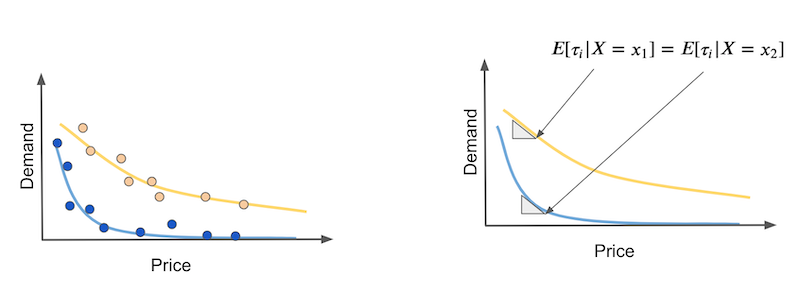


Проблема в том, что **эффект меняется вместе с самим воздействием**. Пусть есть жаркие и холодные дни. Причинная модель должна предсказывать чувствительность, но в нелинейном случае она окажется одинаковой, если смотреть на разные точки кривой (правое изображение).

Простого решения нет. Можно представить форму зависимости и линеаризовать её. Спрос часто описывают как

$$
D_i = \dfrac{C}{P_i^{\alpha}}
$$

где большие $\alpha$ означают более быстрое падение спроса. После логарифмирования зависимость становится линейной:

$$
\log(D)_i = \log(C) - \alpha \log(P_i)
$$

Проверим, улучшает ли логарифм упорядочивание. Часто помогают логарифмы и квадратные корни, но выбор формы требует размышления.

In [15]:
log_train, log_test = train.assign(log_sales=np.log(train['sales']), log_price=np.log(train['price'])), test.assign(log_sales=np.log(test['sales']), log_price=np.log(test['price']))
y_star_log = (log_train['log_price'] - log_train['log_price'].mean()) * (log_train['log_sales'] - log_train['log_sales'].mean())
gain_log_test, _ = price_gain(log_train, log_test, y_star_log, 'log_sales', 'log_price')


def area_over_baseline(curve, baseline):
    share, gain = curve
    return float(np.trapezoid(gain - baseline * share / 100, share)) / 100


slope, elasticity = effect_slope(test, 'sales', 'price'), effect_slope(log_test, 'log_sales', 'log_price')
print('Площадь над случайным порядком в долях среднего эффекта')
print('Исходные шкалы:', round(area_over_baseline(gain_test, slope) / abs(slope), 3))
print('Логарифмы:     ', round(area_over_baseline(gain_log_test, elasticity) / abs(elasticity), 3))

Площадь над случайным порядком в долях среднего эффекта
Исходные шкалы: 0.492
Логарифмы:      0.425


Здесь логарифмирование не улучшило упорядочивание: 0.43 против 0.49. Площадь поделена на средний эффект, чтобы шкалы были сравнимы. Преобразование стоит проверять, а не применять по привычке.

## Causal Impact

### Постановка задачи

Определение причинно-следственного влияния рыночных интервенций — это **важная и актуальная задача** в эконометрике и маркетинге. Многие компании осознали, что систематическое использование метрик влияния для принятия стратегических решений может дать им конкурентное преимущество. Примером является использование "A/B экспериментов" для выявления наиболее эффективных рыночных воздействий с целью распределения ресурсов.

Однако существуют ситуации, когда **рандомизированный эксперимент невозможен**. Например, рекламные кампании часто запускаются по множеству каналов (онлайн и офлайн), что исключает измерение индивидуального воздействия. Кампании могут быть нацелены на целую страну, что запрещает использование географических контролей внутри этой страны. В таких случаях традиционные подходы, такие как разность разностей (difference-in-differences, DD), имеют **ограничения**.

Метод, предложенный в [статье Бродерсена и соавторов (2015)](https://projecteuclid.org/journals/annals-of-applied-statistics/volume-9/issue-1/Inferring-causal-impact-using-Bayesian-structural-time-series-models/10.1214/14-AOAS788.full), **CausalImpact**, направлен на решение этой проблемы. Он позволяет **выводить причинно-следственное влияние** рыночной интервенции, такой как запуск нового продукта или начало рекламной кампании, на основе диффузионно-регрессионной модели пространства состояний.

**Ключевые преимущества подхода CausalImpact**:
*   **Оценка временной эволюции влияния**: В отличие от классических схем разности разностей, модели пространства состояний позволяют **выводить временную эволюцию приписываемого воздействия**.
*   **Байесовский подход**: Метод включает **эмпирические априорные распределения** для параметров в **полностью байесовской обработке**, а также использует **байесовское усреднение моделей** для построения наиболее подходящего синтетического контроля.
*   **Гибкость**: Он гибко учитывает **множественные источники вариации**, включая локальные тренды, сезонность и изменяющееся во времени влияние одновременных ковариат.

### Байесовские структурные временные ряды (BSTS)

Метод CausalImpact основан на **байесовских структурных моделях временных рядов (Bayesian Structural Time Series, BSTS)**, которые являются частным случаем моделей пространства состояний. Эти модели отличаются тем, что они могут гибко адаптироваться к различным предположениям о скрытом состоянии и процессах эмиссии, лежащих в основе наблюдаемых данных.

**Общая форма моделей пространства состояний** определяется парой уравнений:

1.  **Уравнение наблюдений (Observation Equation)**: Связывает наблюдаемые данные с латентным вектором состояния.
$
y_t = Z_t^{T}\alpha_t + \epsilon_{t}
$
2.  **Уравнение состояния (State Equation)**: Описывает эволюцию вектора состояния во времени.
$
\alpha_{t+1} = T_{t}\alpha_t + R_t \eta_t
$

Где:
*   $y_t$ — скалярное наблюдение в момент времени $t$ (например, продажи или посещения сайта).
*   $\alpha_t$ — $d$-мерный латентный вектор состояния в момент времени $t$.
*   $Z_t$ — $d$-мерный выходной вектор.
*   $T_t$ — $d × d$ матрица перехода, описывающая, как состояние $\alpha_t$ эволюционирует к $\alpha_{t+1}$.
*   $R_t$ — $d × q$ контрольная матрица.
*   $\epsilon_{t}$ — скалярная ошибка наблюдения, предполагаемая как $\epsilon_{t} ∼ N(0, σ^2_t)$, независимая от других неизвестных.
*   $η_t$ — $q$-мерная системная ошибка, предполагаемая как $η_t ∼ N(0, Q_t)$, независимая от других неизвестных.
*   $Q_t$ — $q × q$ матрица диффузии состояния.

Структурные модели временных рядов очень **гибкие и модульные**. Они гибкие в том смысле, что очень широкий класс моделей, включая все модели ARIMA, может быть записан в форме пространства состояний. Они модульные в том смысле, что латентное состояние, а также связанные с ним матрицы $Z_t, T_t, R_t$ и $Q_t$ могут быть собраны из **компонентных подмоделей** для захвата важных особенностей данных. Обычно предполагается, что ошибки различных компонентных моделей состояния независимы, что позволяет формировать $\alpha_t$ путем конкатенации индивидуальных компонент состояния, а $T_t$ и $R_t$ становятся блочно-диагональными матрицами.

**Компоненты состояния:**
Модель CausalImpact может включать следующие компоненты состояния:

* **Локальный линейный тренд (Local linear trend)**:

Эта компонента моделирует изменяющийся во времени уровень ($μ_t$) и его ожидаемое изменение (наклон $δ_t$).

$$μ_{t+1} = μ_t + δ_t + η_{μ,t}$$

$$δ_{t+1} = δ_t + η_{δ,t}$$

где $η_{μ,t} ∼ N(0, σ^2_μ)$ и $η_{δ,t} ∼ N(0, σ^2_δ)$ — независимые ошибки.
Это популярный выбор для моделирования трендов, так как он **быстро адаптируется к локальным вариациям**, что желательно для краткосрочных прогнозов. Существует также обобщение этой модели, где наклон демонстрирует стационарность вместо случайного блуждания, балансируя краткосрочную информацию с информацией из далекого прошлого.

* **Сезонность (Seasonality)**:

Эта компонента учитывает регулярные сезонные колебания в данных. Наиболее часто используемая модель в временной области:

$$γ_{t+1} =  - \displaystyle\sum_{s=0}^{S-2} γ_{t-s} + η_{γ,t}$$

где $S$ — количество сезонов (например, $S=7$ для дневного эффекта недели), а $γ_t$ обозначает их совместный вклад в наблюдаемый отклик $y_t$. Среднее значение $γ_{t+1}$ таково, что общий сезонный эффект равен нулю при суммировании за $S$ сезонов. Эта модель может быть обобщена для нескольких сезонных компонент с различными периодами.

* **Одновременные ковариаты со статическими коэффициентами (Contemporaneous covariates with static coefficients)**:

Контрольные временные ряды, которые не подвергались воздействию, **критически важны для получения точных контрфактических прогнозов**, поскольку они объясняют компоненты дисперсии, общие для ряда, включая эффекты других ненаблюдаемых причин. Линейная регрессия является естественным способом включения контрольных рядов в модель. В статической регрессии коэффициенты $β$ остаются постоянными. В байесовском подходе **нет необходимости фиксировать набор ковариат**, благодаря использованию **spike-and-slab априорного распределения**. Оно позволяет интегрировать апостериорную неопределенность относительно того, какие ковариаты включать и как сильно они должны влиять на прогнозы, что **помогает избежать переобучения**.

* **Одновременные ковариаты с динамическими коэффициентами (Contemporaneous covariates with dynamic coefficients)**:

Альтернативой статическим коэффициентам является регрессионная компонента с **динамическими коэффициентами регрессии** для учета изменяющихся во времени связей.

$$x^T_t β_t = \displaystyle \sum_{j=1}^J x_{j,t}β_{j,t}$$

$$β_{j,t+1} = β_{j,t} + η_{β,j,t}$$

где $β_{j,t}$ — коэффициент для $j$-го контрольного ряда, а $η_{β,j,t} ∼ N(0, σ^2_{βj})$ — ошибка случайного блуждания.

Динамические коэффициенты полезны, когда предполагается, что **линейная связь между обрабатываемыми метриками и контролями меняется со временем**.

Структурные модели временных рядов позволяют гибко выбирать подходящие компоненты для тренда, сезонности и регрессии (статической или динамической). Например, наличие или отсутствие сезонности обычно очевидно при визуальном осмотре. Статические коэффициенты привлекательны, когда связь между контролями и обрабатываемой единицей была стабильной в прошлом, так как spike-and-slab априорное распределение может быть эффективно реализовано. Динамические коэффициенты используются, когда эта связь, как считается, меняется со временем.

На рисунке ниже представлена графическая модель для варианта модели пространства состояний со статической регрессией.
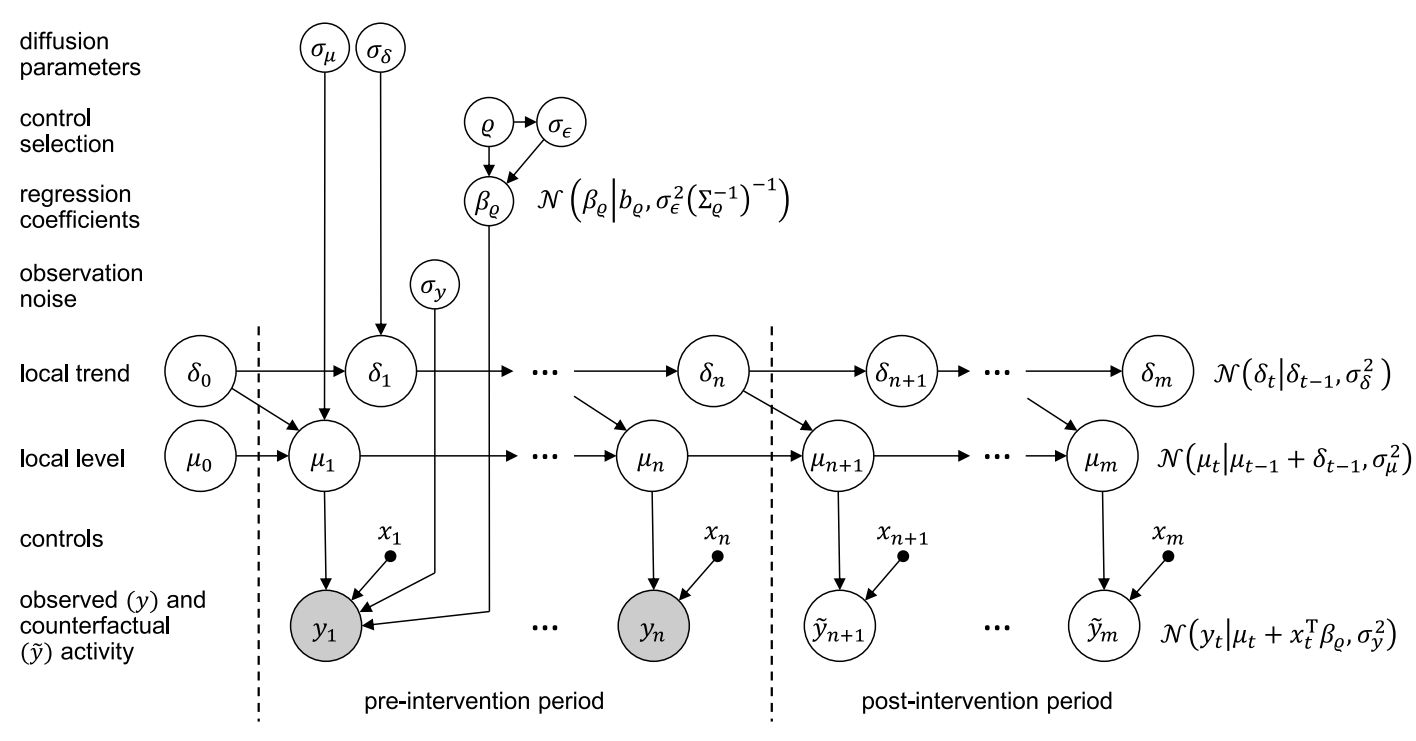

### Принцип работы метода

CausalImpact оценивает причинно-следственное воздействие на основе диффузионно-регрессионной модели пространства состояний, которая **прогнозирует контрфактический отклик**, который произошел бы, если бы не было вмешательства. Он использует три основных шага: построение контрфактической модели, прогнозирование контрфактического сценария и оценку причинно-следственного эффекта.

**Источники информации для построения синтетического контроля**:
1.  **Поведение временного ряда самого отклика** до интервенции.
2.  **Поведение других временных рядов**, которые были предсказуемы для целевого ряда до интервенции (контрольные ряды).
3.  **Априорные знания** о параметрах модели в байесовской структуре.

Эти три источника информации объединяются с использованием модели временных рядов в пространстве состояний.

**Шаг 1: Построение контрфактической модели**

Этот шаг включает в себя **определение и обучение модели BSTS** на данных, предшествующих интервенции (тренировочный период), чтобы она могла точно предсказывать поведение целевого временного ряда $y_t$ в отсутствие вмешательства.

**1. Выбор компонент состояния**

Как обсуждалось выше, модель может включать компоненты для **тренда**, **сезонности** и **регрессии на современных ковариатах**. Выбор зависит от характеристик данных и предметной области.

* Например, для анализа рекламной кампании в статье использовалась комбинация **локального уровня** и **статической регрессионной компоненты**.

* При анализе симулированных данных использовалась **динамическая регрессионная компонента**.

**2. Спецификация априорных распределений (Prior distributions)**

В байесовском подходе мы задаем априорные распределения $p(θ)$ для всех параметров модели $θ$ и $p(α_0|θ)$ для начальных значений состояния $α0$.

* **Для дисперсионных параметров**

Типичное априорное распределение для дисперсии ($σ^2$) — это **обратное гамма-распределение** $\frac{1}{σ^2} ∼ G(\frac{ν}{2}, \frac{s}{2})$

где $G(a, b)$ — гамма-распределение с ожиданием $a/b$. Параметры $ν$ и $s$ можно интерпретировать как априорную сумму квадратов и вес в единицах размера априорной выборки. Часто используются слабые, неинформативные априорные распределения (например, $ν=1$, $s/ν$ — малое значение).

* **Для коэффициентов регрессии (Spike-and-Slab prior)**

Когда имеется много потенциальных ковариат (контрольных рядов $x_t$), модель сама выбирает наиболее подходящий набор с помощью **spike-and-slab априорного распределения**. Это распределение сочетает точечную массу в нуле (the "spike") для неизвестного подмножества нулевых коэффициентов с слабо информативным распределением на дополнительном наборе ненулевых коэффициентов (the "slab").
Пусть $γ = (γ_1, ..., γ_J)$, где $γ_j = 1$, если $β_j ≠ 0$, и $γ_j = 0$ в противном случае. Пусть $β_γ$ обозначает ненулевые элементы вектора $β$.
Априорное распределение факторизуется как:

$$p(γ, β, 1/σ^2_{ε}) = p(γ) p(σ^2_ε | γ) p(β_γ | γ,σ^2_ε)$$

* **"Spike" (выбор переменных)**: Часто используется произведение независимых распределений Бернулли:

$$p(γ) = \displaystyle\prod_{j=1}^J π_j^{γ_j} (1 - π_j)^{1-γ_j}$$

где $π_j$ — априорная вероятность включения регрессора $j$ в модель. Значения $π_j$ можно определить, задав ожидаемый размер модели $M$ (например, $π_j = M/J$).

* **"Slab" (распределение ненулевых коэффициентов)**: Используется сопряженное нормальное-обратное гамма-распределение:

$$β_γ | σ^2_ε ∼ N(b_γ, σ^2_ε (Σ_γ^{-1})^{-1})$$

$$\frac{1}{σ^2_ε} ∼ G(ν_ε/2, s_ε/2)$$

Вектор $b_γ$ кодирует априорное ожидание значения каждого элемента $β$ (часто $b_γ = 0$). Параметры $ν_ε$ и $s_ε$ определяются ожидаемым $R^2$ и количеством наблюдений, которым присваивается вес.

**3. Апостериорный вывод (Posterior Inference)**

Поскольку замкнутых форм для апостериорных распределений не существует, для вывода используется **алгоритм Монте-Карло по Марковским цепям (MCMC)**, в частности, **сэмплер Гиббса**.

* **Шаг увеличения данных (Data-augmentation step)**: симулирует $p(α|y_{1:n}, θ)$ (последовательность состояний $α$ при заданных данных и параметрах) с использованием алгоритма симуляции сглаживателя от Дурбина и Купмана (2002). Этот алгоритм является линейным по количеству временных точек и квадратичным по размерности пространства состояний.

* **Шаг симуляции параметров (Parameter-simulation step)**: симулирует $p(θ|y_{1:n}, α)$ (параметры $θ$ при заданных данных и состояниях). Для большинства компонент это просто благодаря сопряженности априорных распределений. Для статических коэффициентов регрессии $β$ симуляция включает выбор $γ$ из $p(γ|y_{1:n})$ с последующим семплированием $β$ и $σ^2_ε$ из сопряженных формул.

**Шаг 2: Прогнозирование контрфактического сценария**

После обучения модели на пред-интервенционных данных и получения апостериорных выборок параметров ($θ$) и состояний ($α$), следующим шагом является **прогнозирование контрфактического временного ряда**. Контрфактический сценарий — это **ненаблюдаемый рыночный отклик $\tilde{y}_{n+1:m}$**, который произошел бы на обработанном рынке после интервенции в отсутствие воздействия.

**1. Апостериорное предиктивное распределение**

Прогнозирование осуществляется путем симуляции из **апостериорного предиктивного распределения**:

$$p(\tilde{y}_{n+1:m} | y_{1:n}, x_{1:m})$$

Это распределение определяется для той части временного ряда, которая является ненаблюдаемой, то есть для контрфактических откликов $\tilde{y}_{n+1}, ..., \tilde{y}_m$.

**Важно**: Плотность обусловлена только наблюдаемыми данными (до интервенции для целевого ряда $y_{1:n}$) и активностью во всех контрольных рынках (как до, так и во время интервенции $x_{1:m}$).

**2. Байесовское усреднение моделей (Bayesian Model Averaging)**

Модель **не фиксируется на каком-либо конкретном наборе ковариат** или точечных оценках их коэффициентов. Вместо этого, благодаря байесовскому усреднению моделей, **неопределенность относительно выбора ковариат и их влияния интегрируется**. Это помогает избежать произвольного выбора и переобучения.

**3. Когерентность прогнозов**

Апостериорная предиктивная плотность определяется как **когерентное (совместное) распределение** по всем контрфактическим точкам данных, а не как набор поточечных одномерных распределений. Это гарантирует, что сериальная структура, определенная на данных до интервенции, правильно распространяется на траекторию контрфактов. Это крайне важно при формировании сводных статистик, таких как **кумулятивный эффект**.

**Шаг 3: Оценка каузального эффекта**

Имея выборки из апостериорного предиктивного распределения контрфактической активности, можно легко получить выборки **причинно-следственного эффекта**.

**1. Поточечное влияние (Pointwise impact)**

Для каждой выборки $τ$ и для каждого момента времени $t = n+1, ..., m$ (период после интервенции) поточечное влияние $φ^{(τ)}_t$ определяется как разность между наблюдаемым значением $y_t$ и предсказанным контрфактическим значением $\tilde{y}^{(τ)}_t$: $φ^{(τ)}_t := y_t - \tilde{y}^{(τ)}_t$

Это дает выборки из приближенной апостериорной предиктивной плотности эффекта, приписываемого интервенции.

**2. Кумулятивное влияние (Cumulative impact)**

Часто желательно понять **кумулятивный эффект** интервенции с течением времени. С использованием полученных выборок влияния $φ^{(τ)}_t$ можно вычислить кумулятивную сумму для каждой выборки $τ$:

$$\displaystyle\sum_{(t'=n+1)}^t φ^{(τ)}_{t'} \qquad ∀t = n+1, ..., m$$

Эта кумулятивная сумма полезна, когда $y$ представляет собой **потоковую величину**.

**3. Среднее влияние (Running average impact)**

Если $y$ представляет **запасовую величину** (например, общее количество клиентов), кумулятивная сумма может быть неинтерпретируемой. В этом случае можно рассчитать среднее влияние:

$$\frac{1}{t - n} \displaystyle \sum_{t'=n+1}^t φ^{(τ)}_{t'}  \qquad   ∀t = n+1, ..., m$$

Среднее влияние всегда интерпретируемо, но более зависимо от длины постинтервенционного периода.

Таким образом, CausalImpact предоставляет **мощный и гибкий байесовский фреймворк** для оценки причинно-следственного влияния в условиях, когда рандомизированные эксперименты невозможны или непрактичны, используя структурные модели временных рядов и продвинутые байесовские методы для построения синтетических контролей и вывода апостериорных распределений для эффекта.

### Предположения

Метод опирается на условия, без которых результат не имеет смысла. В статье они сформулированы прямо.

* **Контрольные ряды не должны зависеть от вмешательства.** Иначе они несут в себе эффект, и контрфактический прогноз будет загрязнён.
* **Связь контрольных рядов и отклика стабильна** и сохранилась бы после вмешательства.
* **В период после вмешательства нет других событий**, влияющих на отклик и не отражённых в контроле.

Кроме того, важно разделять метод и реализацию. Оригинальный пакет написан на R и использует MCMC и априорное spike-and-slab. Python-пакет `pycausalimpact` устроен иначе: он подгоняет `UnobservedComponents` из `statsmodels` методом максимального правдоподобия с локальным уровнем, и отбора ковариат в нём нет. Поэтому байесовское усреднение моделей, описанное выше, он не делает.

### Пример: повышение ключевой ставки

Посмотрим на объём выданных кредитов в России и ключевую ставку ЦБ РФ. В конце февраля 2022 года ЦБ поднял ставку с 9.5% до 20%. Здесь не получится поставить эксперимент, и естественной контрольной группы нет.

            cred_amt  key_value_perc
date                                
2021-12-31   2060165        0.079091
2022-01-31   1455223        0.085000
2022-02-28   1692068        0.095750
2022-03-31   1298097        0.200000
2022-04-30    859296        0.178571
2022-05-31    985994        0.135000
2022-06-30   1276829        0.100714


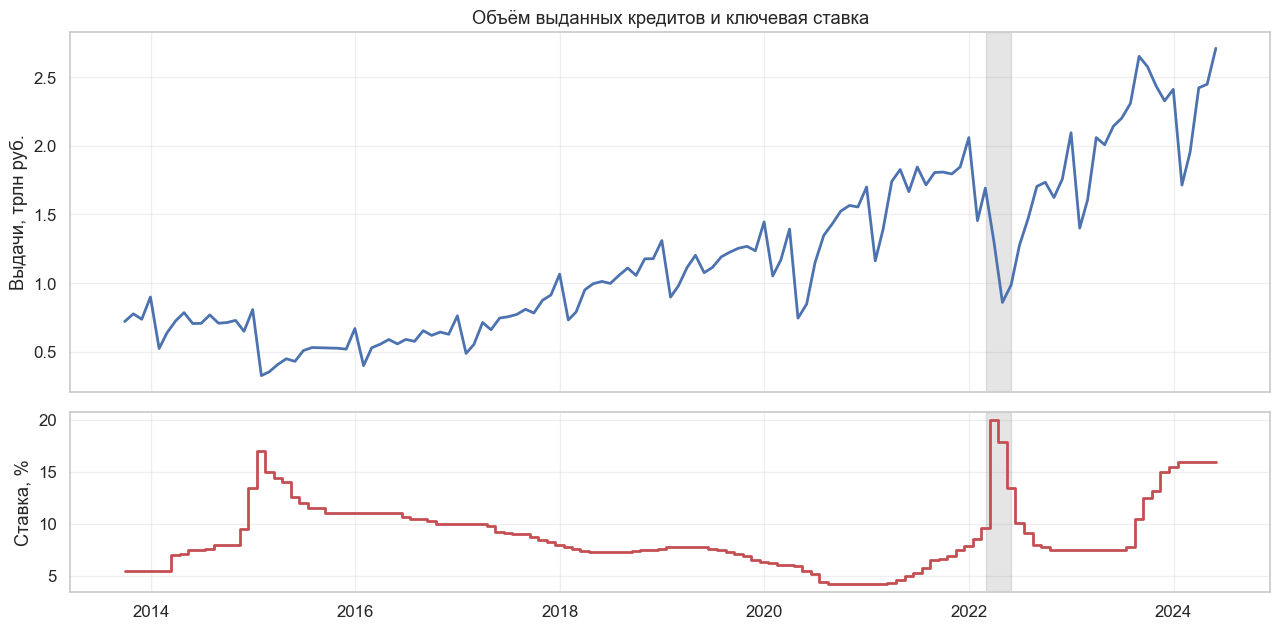

In [16]:
df = pd.read_excel(DATA + 'amt_key.xlsx')
df.columns = ['date', 'cred_amt', 'key_value_perc']
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
print(df.loc['2021-12-31':'2022-06-30'])

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
axes[0].plot(df.index, df['cred_amt'] / 1e6, color=BLUE, lw=2)
axes[0].set_ylabel('Выдачи, трлн руб.')
axes[0].set_title('Объём выданных кредитов и ключевая ставка')
axes[1].step(df.index, df['key_value_perc'] * 100, color=RED, lw=2, where='mid')
axes[1].set_ylabel('Ставка, %')
for ax in axes:
    ax.axvspan(pd.Timestamp('2022-03-01'), pd.Timestamp('2022-05-31'), color=GRAY, alpha=0.2)
plt.tight_layout()

Оценим период март–май 2022 года.

Сначала воспроизведём подход, который часто встречается в примерах. Создадим признаки из календаря, лагов и скользящего среднего цели, добавим ключевую ставку и население и подадим всё в `CausalImpact`. В индексе должна быть дата, первым столбцом идёт цель, а остальные столбцы — это признаки. Данные о населении взяты из [Росстата](https://rosstat.gov.ru/storage/mediabank/Popul_1897+.xlsx).

In [17]:
def create_features(df_in, lags=3, target='cred_amt'):
    tmp = df_in.copy()
    tmp['day'] = tmp.index.day
    tmp['year'] = tmp.index.year
    tmp['month'] = tmp.index.month
    tmp['month_to_new_year'] = 12 - tmp.index.month
    tmp[f'rolling_mean_{lags}'] = tmp[target].rolling(lags, closed='left').mean()
    for lag in range(1, lags + 1):
        tmp[f'lag_{lag}'] = tmp[target].shift(lag)
    return tmp


population = pd.read_excel(DATA + 'rf_population.xlsx').rename(columns={'date': 'year'})
naive_data = create_features(df).dropna()
naive_data = naive_data.reset_index().merge(population, on='year').set_index('date')


def causal_impact_summary(data, pre, post):
    """Запускает пакет и возвращает относительный эффект с интервалом."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        result = CausalImpact(data, pre, post)
    return result, result.summary_data.loc[['rel_effect', 'rel_effect_lower', 'rel_effect_upper'], 'average'].round(3)


naive_impact, naive_effect = causal_impact_summary(naive_data, ['2013-12-31', '2022-02-28'], ['2022-03-31', '2022-05-31'])
print(naive_impact.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    1047795.67         3143387.0
Prediction (s.d.)         1570273.68 (71349.8)4710821.03 (214049.4)
95% CI                    [1437892.38, 1717578.46][4313677.14, 5152735.38]

Absolute effect (s.d.)    -522478.01 (71349.8)-1567434.03 (214049.4)
95% CI                    [-669782.79, -390096.71][-2009348.38, -1170290.14]

Relative effect (s.d.)    -33.27% (4.54%)    -33.27% (4.54%)
95% CI                    [-42.65%, -24.84%] [-42.65%, -24.84%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))


Узкий интервал и «вероятность эффекта 100%» выглядят убедительно. Но у этой спецификации есть серьёзные проблемы.

1. **Ключевая ставка — само воздействие — стоит в ковариатах.** Прогноз после вмешательства использует ставку 20%, то есть это не контрфакт без повышения.
2. **Лаги и скользящее среднее цели после марта 2022 года содержат эффект.** Это прямое нарушение первого предположения.
3. **`month` и `month_to_new_year` строго коллинеарны** и задают сезонность линейно по номеру месяца.
4. **Население** растёт не монотонно: скачок 2015 года связан с включением Крыма, а с 2021 года оно падает. Объём выдач растёт прежде всего из-за инфляции.

Лучшая проверка — **плацебо-дата**. Возьмём март 2021 года, когда резкого шока не было, и применим ту же спецификацию, отрезав данные после февраля 2022 года.

In [18]:
placebo_impact, placebo_effect = causal_impact_summary(naive_data.loc[:'2022-02-28'], ['2013-12-31', '2021-02-28'], ['2021-03-31', '2021-05-31'])
print('Март–май 2022:         ', naive_effect.to_dict())
print('Плацебо март–май 2021: ', placebo_effect.to_dict())

Март–май 2022:          {'rel_effect': -0.333, 'rel_effect_lower': -0.427, 'rel_effect_upper': -0.248}
Плацебо март–май 2021:  {'rel_effect': 0.281, 'rel_effect_lower': 0.196, 'rel_effect_upper': 0.377}


Спецификация находит «эффект» +28% с интервалом [19%, 37%] в марте 2021 года, когда ничего особенного не произошло. Значит, её узким интервалам верить нельзя, а число -33% ничего не значит.

Построим честный вариант напрямую, через `UnobservedComponents`: логарифм выдач, гладкий тренд, сезонность с периодом 12 и никаких признаков, которые могут зависеть от вмешательства. Лог нужен, потому что выдачи растут мультипликативно. Прогноз получаем симуляцией траекторий. Так сохраняется зависимость между месяцами, о которой говорилось выше.

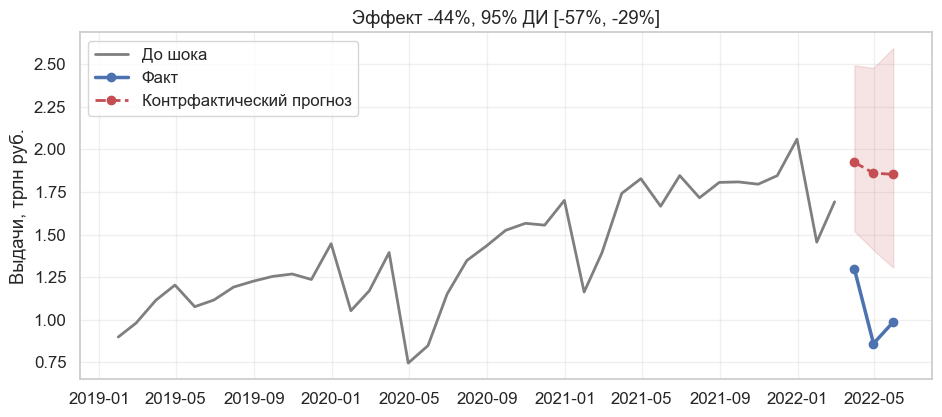

In [19]:
log_credit = np.log(df['cred_amt']).asfreq('ME')


def impact_by_forecast(start, horizon=3, seed=1):
    """Сравнивает факт с симуляциями прогноза, обученного на данных до start."""
    start = pd.Timestamp(start)
    history = log_credit[log_credit.index < start]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = sm.tsa.UnobservedComponents(history.to_numpy(), level='smooth trend', seasonal=12).fit(disp=False, maxiter=300)
    paths = np.exp(fit.simulate(horizon, anchor='end', repetitions=2000, random_state=np.random.default_rng(seed)).reshape(horizon, -1))
    actual = np.exp(log_credit[log_credit.index >= start].iloc[:horizon].to_numpy())
    relative = actual.mean() / paths.mean(axis=0) - 1
    return {'Начало': start, 'Эффект': relative.mean(), 'ДИ 2.5%': np.percentile(relative, 2.5), 'ДИ 97.5%': np.percentile(relative, 97.5), 'paths': paths, 'actual': actual}


impact_2022 = impact_by_forecast('2022-03-31')

history = df['cred_amt'].loc['2019-01-31':'2022-02-28'] / 1e6
future = pd.date_range('2022-03-31', periods=3, freq='ME')
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(history.index, history, color=GRAY, lw=2, label='До шока')
ax.plot(future, impact_2022['actual'] / 1e6, 'o-', color=BLUE, lw=2.5, label='Факт')
ax.plot(future, np.median(impact_2022['paths'], axis=1) / 1e6, 'o--', color=RED, lw=2, label='Контрфактический прогноз')
ax.fill_between(future, *np.percentile(impact_2022['paths'], [2.5, 97.5], axis=1) / 1e6, color=RED, alpha=0.15)
ax.set_ylabel('Выдачи, трлн руб.')
ax.set_title(f"Эффект {impact_2022['Эффект']:.0%}, 95% ДИ [{impact_2022['ДИ 2.5%']:.0%}, {impact_2022['ДИ 97.5%']:.0%}]")
ax.legend();

Теперь плацебо по многим датам. Повторим расчёт для окон каждые три месяца с 2017 по 2021 годы.

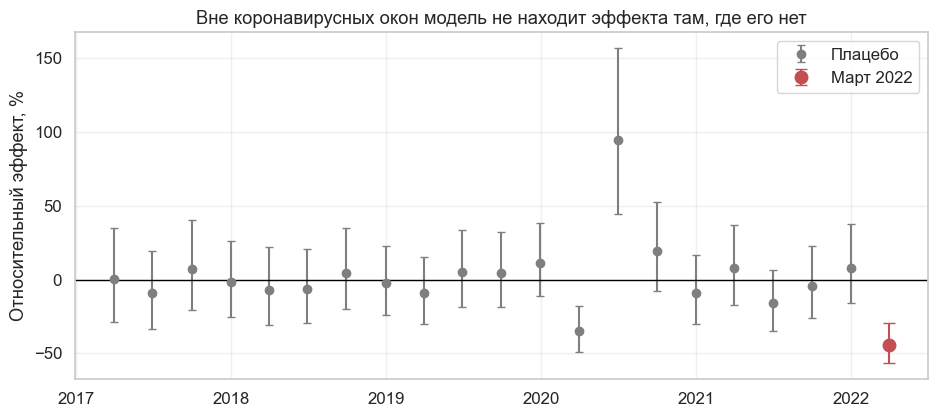

Значимых плацебо: 2 из 20
    Начало  Эффект
2020-03-31  -0.350
2020-06-30   0.949


In [20]:
placebo_dates = pd.date_range('2017-03-31', '2021-12-31', freq='3ME')
placebo = pd.DataFrame([{k: v for k, v in impact_by_forecast(date).items() if k not in ('paths', 'actual')} for date in placebo_dates])
placebo['Значимо'] = (placebo['ДИ 2.5%'] > 0) | (placebo['ДИ 97.5%'] < 0)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.errorbar(placebo['Начало'], placebo['Эффект'] * 100, yerr=[(placebo['Эффект'] - placebo['ДИ 2.5%']) * 100, (placebo['ДИ 97.5%'] - placebo['Эффект']) * 100],
            fmt='o', color=GRAY, capsize=3, label='Плацебо')
ax.errorbar([impact_2022['Начало']], [impact_2022['Эффект'] * 100],
            yerr=[[(impact_2022['Эффект'] - impact_2022['ДИ 2.5%']) * 100], [(impact_2022['ДИ 97.5%'] - impact_2022['Эффект']) * 100]],
            fmt='o', color=RED, capsize=4, ms=9, label='Март 2022')
ax.axhline(0, color='black', lw=1)
ax.set_ylabel('Относительный эффект, %')
ax.set_title('Вне коронавирусных окон модель не находит эффекта там, где его нет')
ax.legend()
plt.show()

print('Значимых плацебо:', int(placebo['Значимо'].sum()), 'из', len(placebo))
print(placebo.loc[placebo['Значимо'], ['Начало', 'Эффект']].round(3).to_string(index=False))

Модель проходит проверку: из 20 плацебо-окон значимы только 2, и оба связаны с коронавирусом: апрель 2020 года и восстановление после него. В спокойные периоды эффект в пределах ±20% и интервалы включают ноль. На этом фоне -44% с интервалом от -57% до -29% для марта–мая 2022 года выглядит настоящим сдвигом. Обратите внимание, что ширина интервала стала честной: около 30 процентных пунктов вместо 16.

Остаётся третье предположение, и его данные не проверят. В марте 2022 года одновременно подняли ставку, ввели санкции, изменились ожидания, банки ужесточили условия. Ставка к тому же реагирует на шок и сама им вызвана. Поэтому эта оценка показывает **эффект всего шока марта 2022 года**, а не эффект ключевой ставки. Разделить их одним рядом без контрольных единиц невозможно.

### Контрольные ряды

Покажем, зачем нужны контрольные ряды и что происходит, если они не чистые. Смоделируем отклик с контрольным рядом и настоящим эффектом -10. Ползунок задаёт, какая доля эффекта попала и в контрольный ряд.

In [21]:
def simulate_contamination(share, effect=-10, n=120, post=20, seed=4):
    """Оценивает эффект локальным уровнем с контролем, который частично затронут воздействием."""
    local = np.random.default_rng(seed)
    common = np.cumsum(local.normal(0.3, 1, n))
    control = common + local.normal(0, 0.5, n)
    y = 20 + common + local.normal(0, 0.5, n)
    y[-post:] += effect
    control[-post:] += share * effect

    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = sm.tsa.UnobservedComponents(y[:-post], level='llevel', exog=control[:-post]).fit(disp=False, maxiter=300)
    forecast = fit.get_forecast(post, exog=control[-post:].reshape(-1, 1))
    return y, forecast.predicted_mean, forecast.conf_int(alpha=0.05), n - post


def plot_contamination(ax, share):
    y, prediction, interval, start = simulate_contamination(share)
    grid = np.arange(len(y))
    ax.plot(grid, y, color=BLUE, lw=2, label='Отклик')
    ax.plot(grid[start:], prediction, color=RED, lw=2, label='Контрфакт')
    ax.fill_between(grid[start:], interval[:, 0], interval[:, 1], color=RED, alpha=0.15)
    ax.axvline(start, color=GRAY, ls=':')
    ax.set_title(f'Загрязнение {share:.0%}: оценка {(y[start:] - prediction).mean():.1f} при настоящих -10', fontsize=12)
    ax.set_xlabel('Период')


def contamination_demo(share=0.0):
    fig, ax = plt.subplots(figsize=(9, 4.3))
    plot_contamination(ax, share)
    ax.legend()
    plt.show()


interact(contamination_demo, share=FloatSlider(value=0, min=0, max=1, step=0.1, description='Доля'));

Статичная версия для трёх долей.

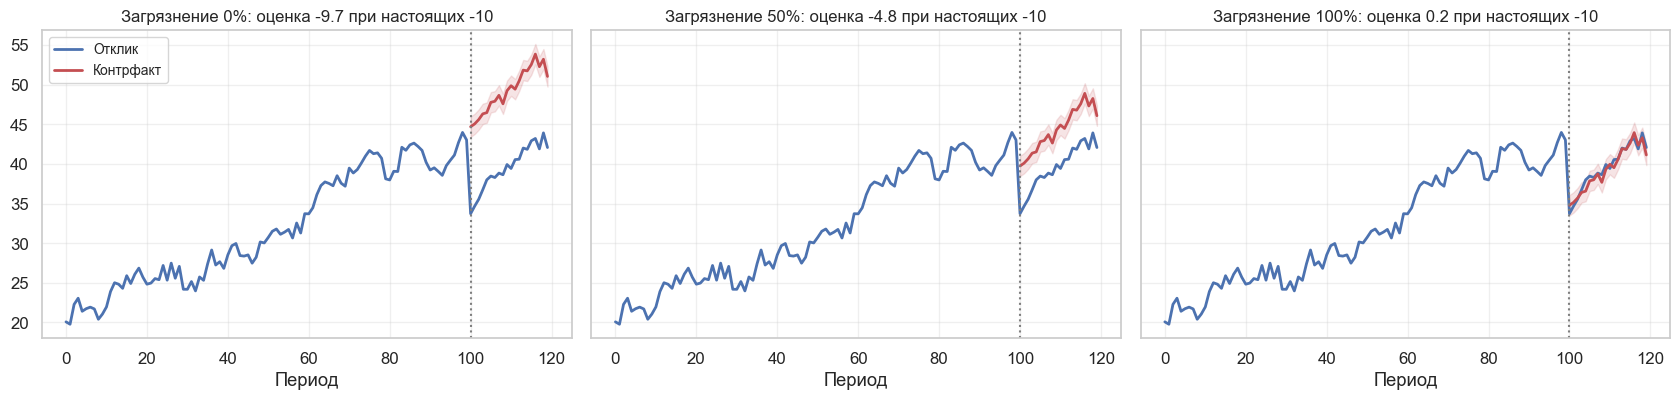

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, share in zip(axes, [0, 0.5, 1]):
    plot_contamination(ax, share)
axes[0].legend(fontsize=10)
plt.tight_layout()

Если контроль чистый, оценка близка к -10 и интервал узкий: контрольный ряд объясняет общую динамику. Если половина эффекта попала в контроль, модель находит примерно половину эффекта. При полном загрязнении эффект исчезает совсем. Именно это делали лаги цели в первой спецификации.

## Заключение

| Метод | Что оценивает | Что нужно | Как проверить |
| :--- | :--- | :--- | :--- |
| Двойная робастность | ATE | Нет неизмеренных конфаундеров, верна хотя бы одна модель | Перекрытие, баланс, сравнение с другими оценками |
| Трансформация цели | CATE | Рандомизация или известный скор | Кривая прироста на отложенных данных |
| Causal Impact | Эффект на один ряд по времени | Чистые контроли, стабильная связь, нет других шоков | Плацебо-даты, чувствительность к спецификации |

Главное из лекции:

* двойная робастная оценка спасает от ошибки в одной из двух моделей, но не в обеих и не от пропущенной переменной;
* при гибких ML-моделях нужен кросс-фиттинг;
* CATE нельзя проверить напрямую, поэтому используют кривую прироста и всегда смотрят на отложенные данные;
* трансформированная цель шумна, и вычитание прогноза исхода снижает шум;
* в Causal Impact нельзя подавать ковариаты, зависящие от вмешательства, в том числе лаги цели;
* один красивый интервал ничего не доказывает, пока модель не прошла плацебо-даты.